In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
import pandas as pd

df = pd.read_csv("data/Sample - Superstore.csv", encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [8]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [9]:
# Statistical summary of numerical columns
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [10]:
# Convert date columns to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check data types
print("\nUpdated data types:")
print(df.dtypes)

Duplicate rows: 0

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Updated data types:
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name        

In [11]:
# Calculate Key Performance Indicators (KPIs)

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()

print("===== SALES PERFORMANCE =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")

===== SALES PERFORMANCE =====
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Quantity Sold: 37,873


In [12]:
# Sales and Profit by Category

category_analysis = df.groupby("Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).sort_values(by="Sales", ascending=False)

category_analysis

,Sales,Profit,Quantity
Category,,,
Technology,836154.0330,145454.9481,6939
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906


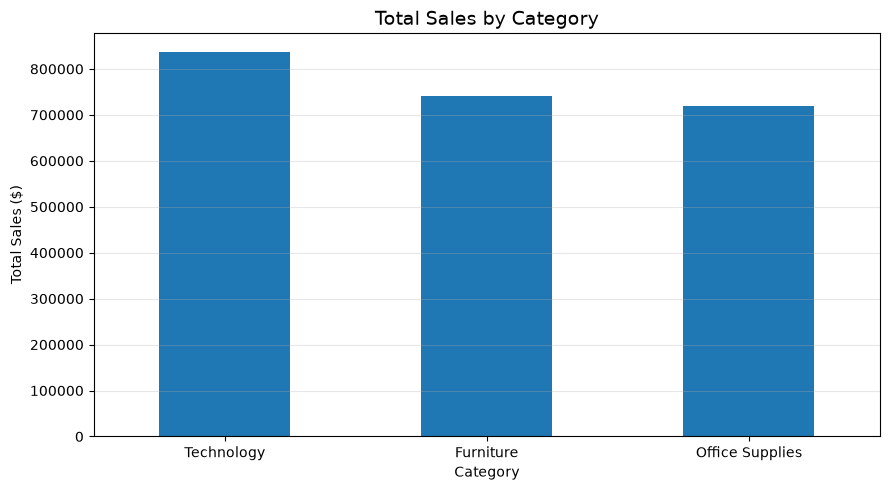

In [13]:
import matplotlib.pyplot as plt

# Sales by Category
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '../images/profit_by_category.png'

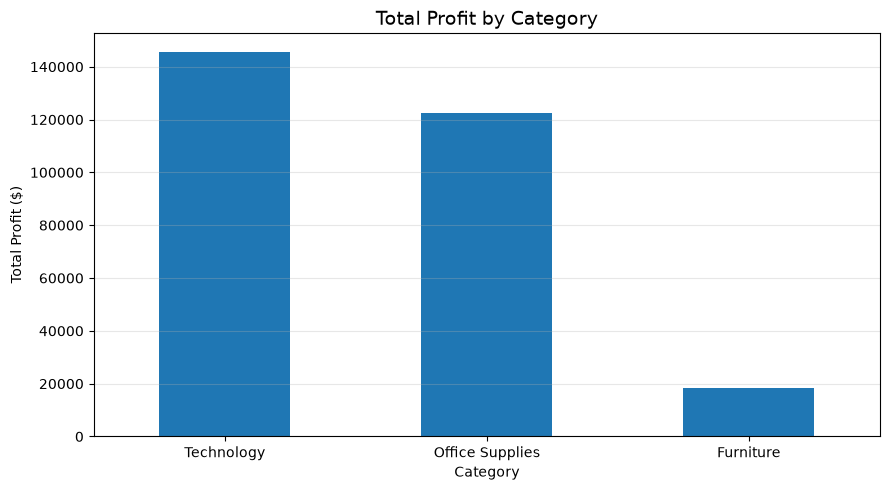

In [14]:
# Calculate Profit by Category
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

# Create the chart
plt.figure(figsize=(9, 5))

category_profit.plot(kind="bar")

plt.title("Total Profit by Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig("../images/profit_by_category.png", dpi=300, bbox_inches="tight")

plt.show()

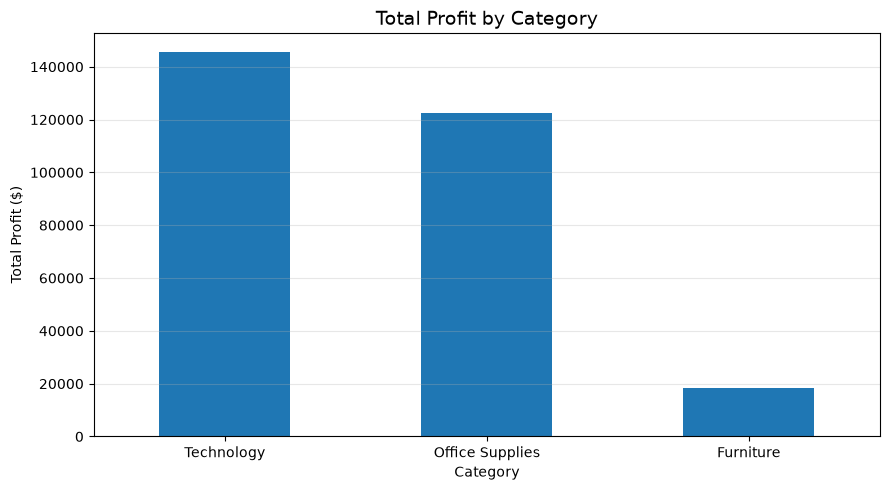

In [15]:
# Calculate Profit by Category
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

# Create the chart
plt.figure(figsize=(9, 5))

category_profit.plot(kind="bar")

plt.title("Total Profit by Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save chart in images folder
plt.savefig("images/profit_by_category.png", dpi=300, bbox_inches="tight")

plt.show()

In [16]:
# Analyze Sales and Profit by Sub-Category

subcategory_analysis = df.groupby("Sub-Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).sort_values(by="Profit", ascending=True)

subcategory_analysis

,Sales,Profit,Quantity
Sub-Category,,,
Tables,206965.5320,-17725.4811,1241
Bookcases,114879.9963,-3472.5560,868
Supplies,46673.5380,-1189.0995,647
Fasteners,3024.2800,949.5182,914
Machines,189238.6310,3384.7569,440
Labels,12486.3120,5546.2540,1400
Art,27118.7920,6527.7870,3000
Envelopes,16476.4020,6964.1767,906
Furnishings,91705.1640,13059.1436,3563


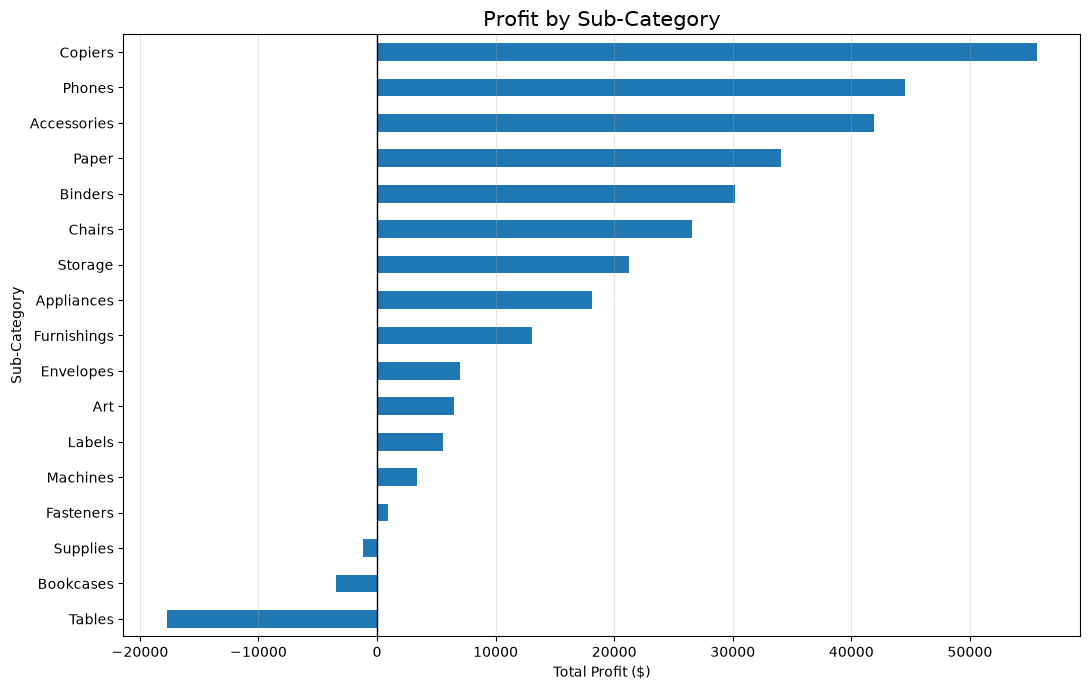

In [17]:
# Profit by Sub-Category
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()
subcategory_profit = subcategory_profit.sort_values()

# Create chart
plt.figure(figsize=(11, 7))

subcategory_profit.plot(kind="barh")

plt.axvline(x=0, color="black", linewidth=1)

plt.title("Profit by Sub-Category", fontsize=15)
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig("images/profit_by_subcategory.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [18]:
# Calculate Profit by Sub-Category
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()

# Sort from lowest to highest profit
subcategory_profit = subcategory_profit.sort_values()

# Display results
print(subcategory_profit)

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64


In [19]:
# Analyze Sales and Profit by Region

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum",
    "Order ID": "nunique"
})

# Sort by Sales
region_analysis = region_analysis.sort_values(
    by="Sales", ascending=False
)

print(region_analysis)

               Sales       Profit  Quantity  Order ID
Region                                               
West     725457.8245  108418.4489     12266      1611
East     678781.2400   91522.7800     10618      1401
Central  501239.8908   39706.3625      8780      1175
South    391721.9050   46749.4303      6209       822


In [20]:
# Monthly Sales Analysis

df["Year-Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = df.groupby("Year-Month")["Sales"].sum()

print(monthly_sales)

Year-Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


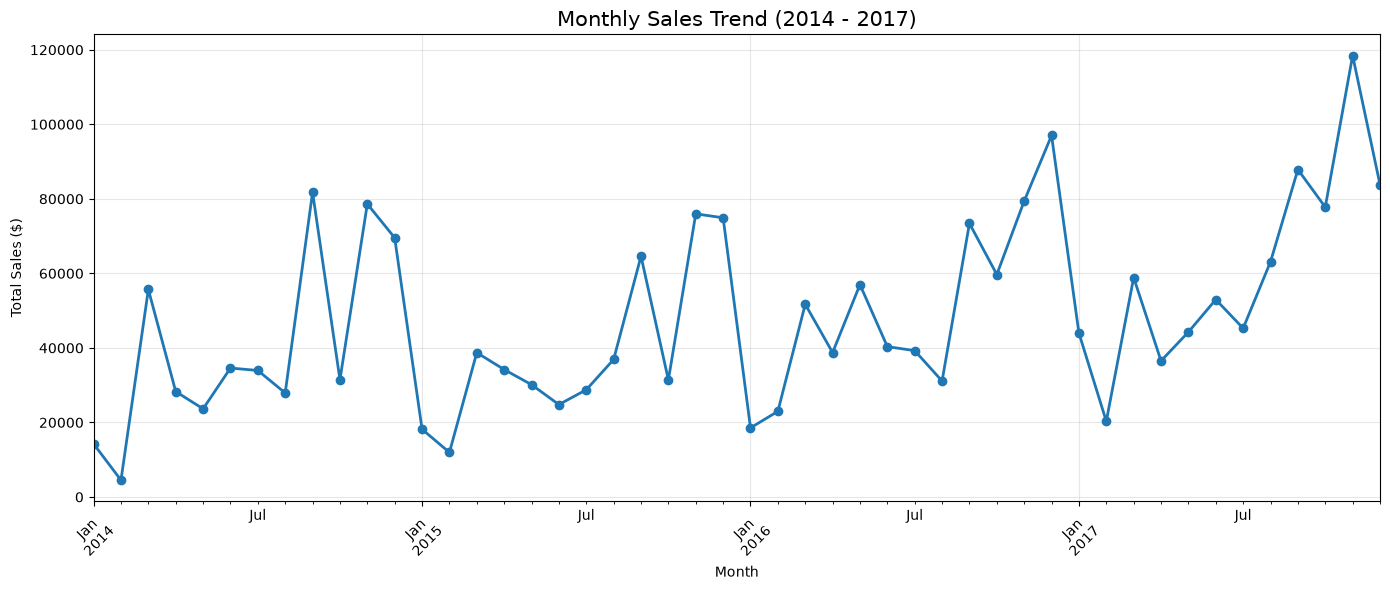

In [21]:
# Monthly Sales Trend

plt.figure(figsize=(14, 6))

monthly_sales.plot(kind="line", marker="o", linewidth=2)

plt.title("Monthly Sales Trend (2014 - 2017)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig("images/monthly_sales_trend.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [22]:
# Yearly Sales Analysis

yearly_sales = df.groupby(df["Order Date"].dt.year)["Sales"].sum()

print(yearly_sales)

Order Date
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


In [23]:
# Sales and Profit by Customer Segment

segment_analysis = df.groupby("Segment").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum",
    "Customer ID": "nunique"
})

segment_analysis = segment_analysis.sort_values(
    by="Sales",
    ascending=False
)

print(segment_analysis)

                    Sales       Profit  Quantity  Customer ID
Segment                                                      
Consumer     1.161401e+06  134119.2092     19521          409
Corporate    7.061464e+05   91979.1340     11608          236
Home Office  4.296531e+05   60298.6785      6744          148


In [24]:
# Top 10 Customers by Sales

top_customers = df.groupby("Customer Name").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Order ID": "nunique"
})

top_customers = top_customers.sort_values(
    by="Sales",
    ascending=False
).head(10)

print(top_customers.round(2))

                       Sales   Profit  Order ID
Customer Name                                  
Sean Miller         25043.05 -1980.74         5
Tamara Chand        19052.22  8981.32         5
Raymond Buch        15117.34  6976.10         6
Tom Ashbrook        14595.62  4703.79         4
Adrian Barton       14473.57  5444.81        10
Ken Lonsdale        14175.23   806.86        12
Sanjit Chand        14142.33  5757.41         9
Hunter Lopez        12873.30  5622.43         6
Sanjit Engle        12209.44  2650.68        11
Christopher Conant  12129.07  2177.05         5
